### Проверка ядра `haps_geom`

Проверяет: интерпретатор ядра, CUDA, версии ключевых пакетов, загрузку foundation/deep
моделей и самоподобие (hibou_l/phikon ≈ 1.0, lpips_cellpose ≈ 0.0).

In [3]:
# # Проверка окружения ядра `haps_geom`.
# import sys, os

# # на случай запуска этой ячейки отдельно (после рестарта ядра) — продублируем HF-env
# os.environ.setdefault("HF_HUB_OFFLINE", "1")
# os.environ.setdefault("HF_HUB_CACHE", "/trinity/home/vladislav.kozlovskiy/.cache/huggingface/hub")
# _tok = "/trinity/home/f.gubanov/.cache/huggingface/token"
# if os.path.exists(_tok) and "HF_TOKEN" not in os.environ:
#     os.environ["HF_TOKEN"] = open(_tok).read().strip()
# os.environ.setdefault("CELLPOSE_LOCAL_MODELS_PATH", os.path.expanduser("~/.cellpose/models"))
# sys.path.insert(0, "/beegfs/home/f.gubanov/f.gubanov/bimai_lab/HAPS_v1_Vladislav")

# print("sys.executable:", sys.executable)
# print("sys.prefix:", sys.prefix)

# import torch
# print("cuda available:", torch.cuda.is_available())
# if torch.cuda.is_available():
#     print("gpu:", torch.cuda.get_device_name(0))

# import importlib.metadata as md
# for p in ["torch", "transformers", "cellpose", "albumentations", "seaborn", "ipykernel", "lpips", "piq", "DISTS-pytorch"]:
#     try:
#         print(f"  {p}: {md.version(p)}")
#     except Exception:
#         print(f"  {p}: MISSING")

# from scripts.foundation_metrics import calc_foundation
# from scripts.deep_metrics import calc_lpips_cellpose, LPIPSCellpose

# device = "cuda" if torch.cuda.is_available() else "cpu"
# x = torch.rand(1, 3, 224, 224, device=device)

# print("hibou_l self-sim (ожид. ~1.0):",
#       round(calc_foundation(x, x, "hibou_l", agg="cos", feature="layer_20", device=device), 5))
# print("phikon self-sim (ожид. ~1.0):",
#       round(calc_foundation(x, x, "phikon", agg="cos", feature="layer_1", device=device), 5))

# lpips_cellpose_model = LPIPSCellpose(device=device)
# print("lpips_cellpose self-sim (ожид. ~0.0):",
#       round(calc_lpips_cellpose(x, x, lpips_cellpose_model), 5))

# print("VERIFY OK")

# Устойчивость метрик сходства H&E к геометрическим искажениям

Эксперимент по протоколу `geom_transform_exp.md`. 

Логика вынесена в `scripts/geom_robustness.py`; здесь — конфигурация, визуализация и анализ.

Все метрики приведены к **similarity** (больше = лучше): distance-метрики
(DISTS/LPIPS) обёрнуты знаком минус. Препроцессинг задаётся **на метрику**
(`metric_specs`), что позволяет смешивать gray-классику и rgb-метрики.


In [3]:
%load_ext autoreload
%autoreload 2

import sys, os
os.environ.setdefault("NO_ALBUMENTATIONS_UPDATE", "1")  # отключить сетевой чек albumentations

# gated HF-модели (hibou-L) — читаем офлайн из lab-кэша; токен из домашней папки
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("HF_HUB_CACHE", "/trinity/home/vladislav.kozlovskiy/.cache/huggingface/hub")
_tok = "/trinity/home/f.gubanov/.cache/huggingface/token"
if os.path.exists(_tok) and "HF_TOKEN" not in os.environ:
    os.environ["HF_TOKEN"] = open(_tok).read().strip()

sys.path.insert(0, "/beegfs/home/f.gubanov/f.gubanov/bimai_lab/HAPS_v1_Vladislav")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import lpips
from DISTS_pytorch import DISTS

from scripts.metrics import *
from scripts.preprocessing import MetricInput, Preprocessor
from scripts.dataset_class import SimpleDataset
from scripts.geom_robustness import *

device = "cuda" if torch.cuda.is_available() else "cpu"
device

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'cuda'

In [2]:
import albumentations as A

A.__version__

'2.0.8'

## Utils / визуализация

In [4]:
def plot_images(imgs, axs, grid=False, cbar=True, **kwargs):
    if len(imgs) != len(axs):
        raise ValueError("Number of images != len(axs)")
    for ax, img in zip(axs, imgs):
        im = ax.imshow(img, **kwargs)
        if len(img.shape) < 3 and cbar:
            fig = ax.figure
            fig.colorbar(im, ax=ax)
        if grid:
            ax.grid(color='black', linestyle='-', linewidth=0.4)

In [5]:
def visualize_distortion_series(dataset, patch_idx, dist_type, levels, preprocessor=None, preproc_config=None, crop_margin=16):
    """Визуализирует пайплайн: Raw -> Distortion -> Crop -> Preprocessing."""
    item = dataset[patch_idx]
    f_patch, _, _, _, _ = dataset.unpack_item(item)

    n_imgs = len(levels) + 1
    fig, axes = plt.subplots(1, n_imgs, figsize=(5 * n_imgs, 5))

    f_patch_cropped = crop_borders(f_patch, crop_margin)
    if preprocessor and preproc_config:
        inp_0 = preprocessor.process(f_patch_cropped, f_patch_cropped, preproc_config)
        img_0_show = inp_0.src_np
    else:
        img_0_show = f_patch_cropped

    dist_imgs, dist_params = [], []
    for i, level in enumerate(levels):
        dist_img_full, params = apply_distortion(f_patch, dist_type, level, seed=i * 1000)
        dist_img_cropped = crop_borders(dist_img_full, crop_margin)
        if preprocessor and preproc_config:
            # process(f=ref, w=dist) -> src_np=dist (показываем искажённый)
            inp_k = preprocessor.process(f_patch_cropped, dist_img_cropped, preproc_config)
            img_k_show = inp_k.src_np
        else:
            img_k_show = dist_img_cropped
        dist_imgs.append(img_k_show)
        dist_params.append(params)

    plot_images([img_0_show] + dist_imgs, axes, grid=True, cbar=False)
    axes[0].set_title(f"Original (Patch {patch_idx})")
    for ax, param in zip(axes[1:], dist_params):
        ax.set_title(f"{dist_type} = {param}")

    plt.tight_layout()
    plt.show()

## Dataset

In [6]:
full_df_path = '/beegfs/home/f.gubanov/f.gubanov/bimai_lab/filtration_imgs/exp_full.csv'
full_dataset = SimpleDataset(full_df_path, dist_col='Similarity_Score', class_col='class3', return_meta=True)
len(full_dataset)

512

## Уровни искажений + препроцессор

In [7]:
GRAY_CFG = {'normalization': True, 'channel_mode': 'gray', 'flip_intensity': False, 
            'match_histogram': False, 'clahe': False, 'smoothing': False, 'binary_mask': False,
        }

RGB_CFG = {**GRAY_CFG, 'channel_mode': 'rgb'}

stages = {
    "shift":   [0.005, 0.01, 0.02, 0.04],  # ~1.3px ... 10.2px
    "rotate":  [2, 4, 8, 12],              # градусы
    "elastic": [1, 3, 6, 9, 12],           # magnitude GridElasticDeform
}

crop_margin = 16   # 256 -> 224
n_seeds = 5

preprocessor = Preprocessor(device=device)

## Визуальная проверка трансформаций

Картинки вида $I_0, I_1, \ldots, I_k$ - в одной строке $k$ столбцов - деформации одного типа (разного уровня) для одного патча.

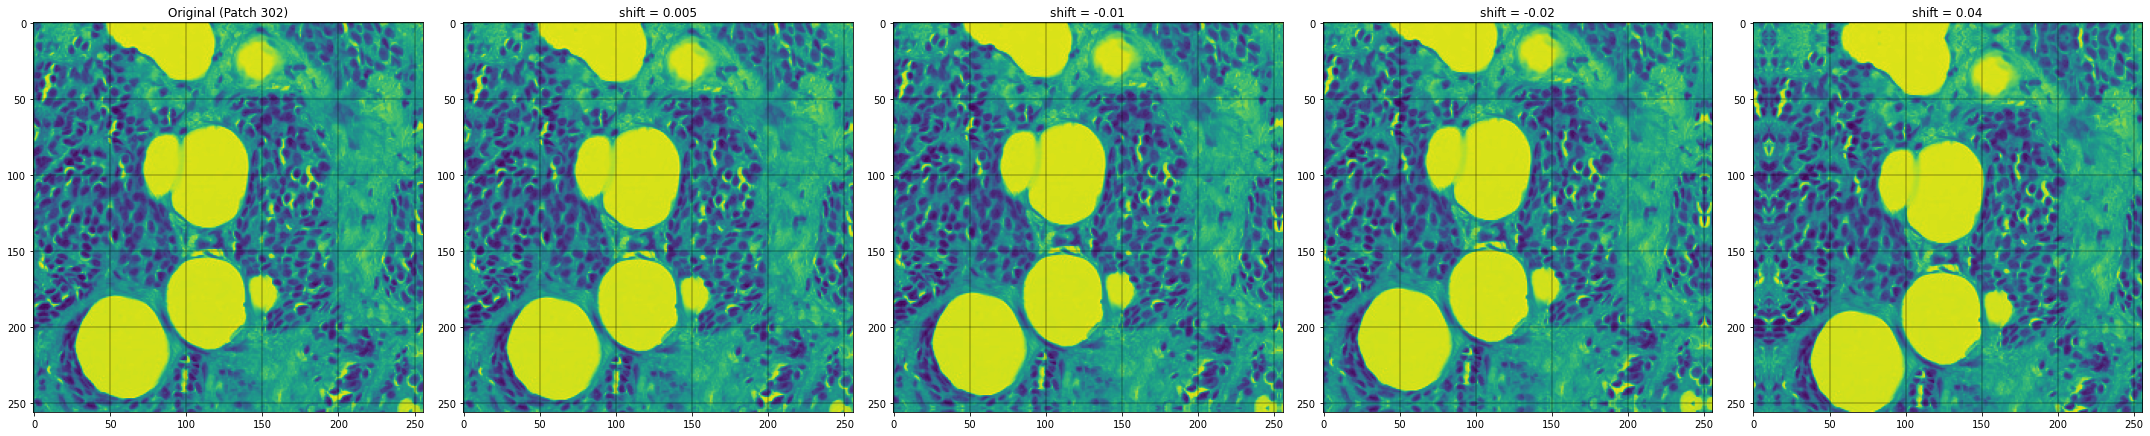

In [30]:
dist_type = "shift"
visualize_distortion_series(full_dataset, 302, dist_type, stages[dist_type], preprocessor=preprocessor, preproc_config=GRAY_CFG, crop_margin=0)

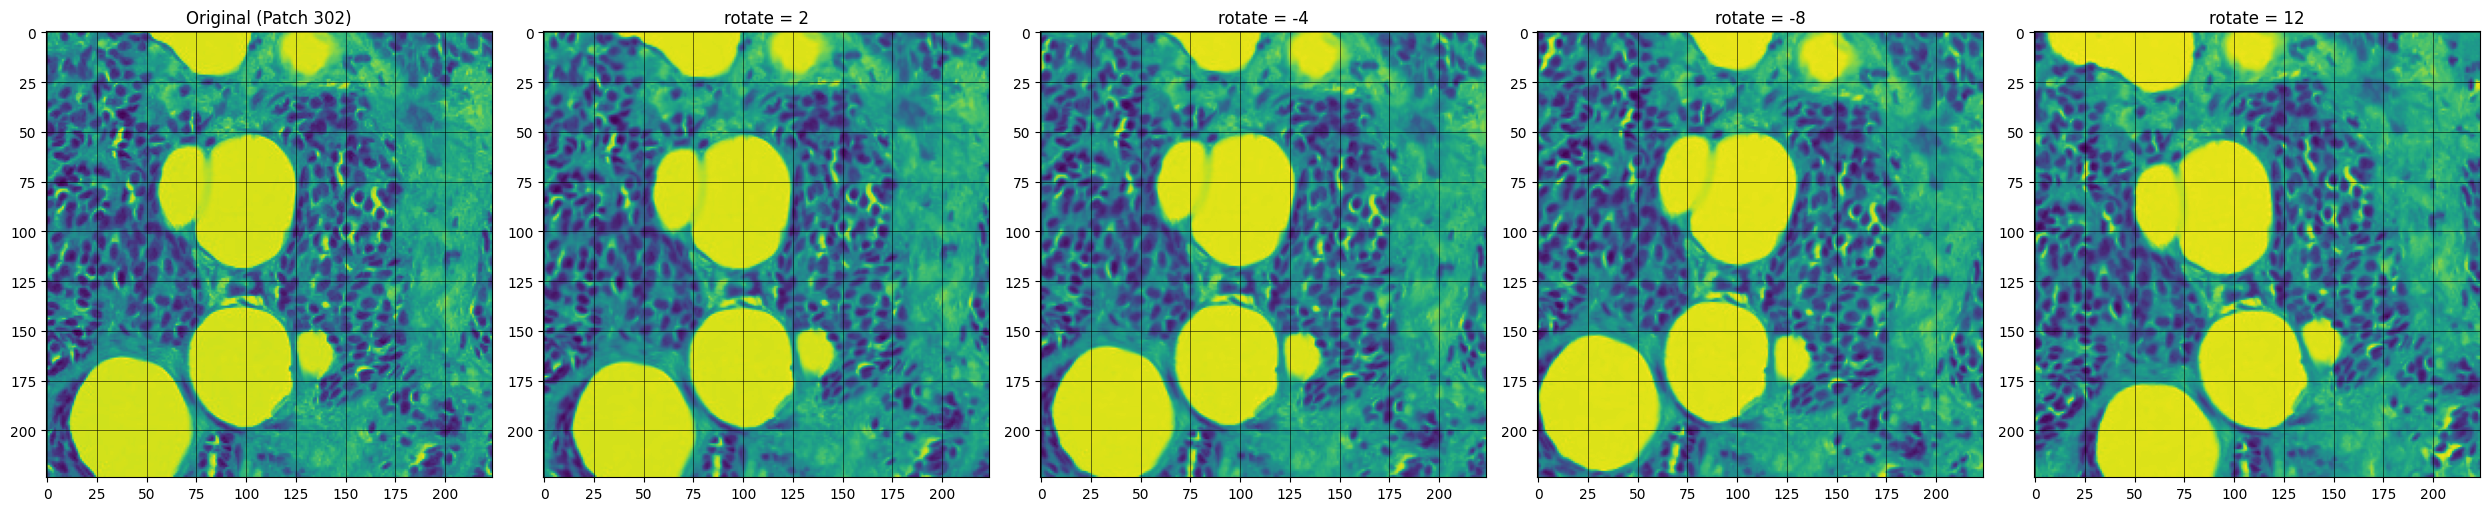

In [13]:
dist_type = "rotate"
visualize_distortion_series(full_dataset, 302, dist_type, stages[dist_type], preprocessor=preprocessor, preproc_config=GRAY_CFG, crop_margin=crop_margin)

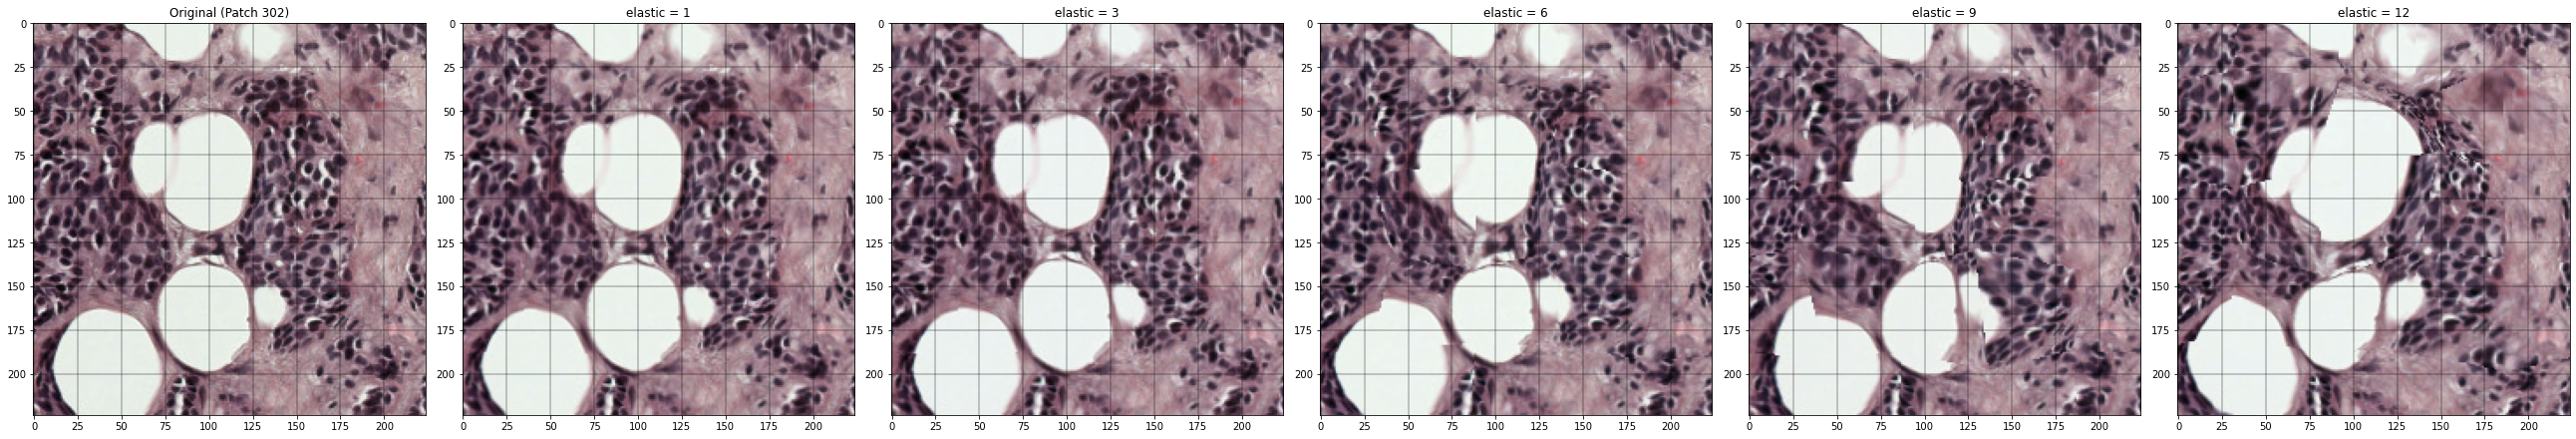

In [45]:
dist_type = "elastic"
visualize_distortion_series(full_dataset, 302, dist_type, stages[dist_type], preprocessor=preprocessor, preproc_config=RGB_CFG, crop_margin=crop_margin)

## Метрики (similarity, per-metric config)

In [10]:
# D_loss_fn = DISTS().eval().to(device)
# L_squeeze_loss_fn = lpips.LPIPS(net='squeeze', lpips=False).eval().to(device)
# L_alex_loss_fn = lpips.LPIPS(net='alex', lpips=True).eval().to(device)
# L_vgg_loss_fn = lpips.LPIPS(net='vgg', lpips=True).eval().to(device)

# Все метрики -> similarity (больше = лучше). Distance (DISTS/LPIPS) инвертируются.
metric_specs = {
#     'ssim_w7':  {'fn': lambda inp: calc_ssim(inp.src_np, inp.trg_np, inp.mask_np), 'config': GRAY_CFG},
    
#     'ssim_w31': {'fn': lambda inp: calc_ssim(inp.src_np, inp.trg_np, inp.mask_np, win_size=31), 'config': GRAY_CFG},
    
#     'psnr':     {'fn': lambda inp: calc_psnr(inp.src_np, inp.trg_np, inp.mask_np), 'config': GRAY_CFG},
    
#     'mi':       {'fn': lambda inp: calc_mi(inp.src_np, inp.trg_np, inp.mask_np), 'config': GRAY_CFG},
    
#    'ncc':      {'fn': lambda inp: calc_ncc(inp.src_np, inp.trg_np, inp.mask_np), 'config': GRAY_CFG},
    
#     'ms-ssim':  {'fn': lambda inp: calc_ms_ssim(inp.src_t, inp.trg_t, inp.mask_t), 'config': GRAY_CFG},
    
#     'fsim':     {'fn': lambda inp: calc_fsim(inp.src_t, inp.trg_t, chromatic=False), 'config': GRAY_CFG},
    
#     'fsimc':    {'fn': lambda inp: calc_fsim(inp.src_t, inp.trg_t, chromatic=True), 'config': RGB_CFG},
    
#     'dists':    {'fn': lambda inp: -calc_dists(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, D_loss_fn), 'config': GRAY_CFG},
#     'dists_rgb':    {'fn': lambda inp: -calc_dists(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, D_loss_fn), 'config': RGB_CFG},
    
#     'lpips_squeeze_avg': {'fn': lambda inp: -calc_lpips(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, L_squeeze_loss_fn), 'config': GRAY_CFG},
#     'lpips_squeeze_avg_rgb': {'fn': lambda inp: -calc_lpips(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, L_squeeze_loss_fn), 'config': RGB_CFG},
    
#     'lpips_alex_lin': {'fn': lambda inp: -calc_lpips(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, L_alex_loss_fn), 'config': GRAY_CFG},
#     'lpips_alex_lin_rgb': {'fn': lambda inp: -calc_lpips(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, L_alex_loss_fn), 'config': RGB_CFG},
    
#     'lpips_vgg_lin':     {'fn': lambda inp: -calc_lpips(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, L_vgg_loss_fn), 'config': GRAY_CFG},
#     'lpips_vgg_lin_rgb':     {'fn': lambda inp: -calc_lpips(inp.src_t, inp.trg_t, inp.mask_t, inp.bg_val, L_vgg_loss_fn), 'config': RGB_CFG},
}
# list(metric_specs.keys())

## Proposed метрики (hibou_l / phikon / lpips_cellpose)

Все — similarity (больше = лучше). foundation-метрики считаются на `rgb` без препроцессинга
(`FOUNDATION_CFG`, normalization=False); `lpips_cellpose` — на `gray`+norm (см. конфиг).

In [11]:
from scripts.foundation_metrics import calc_foundation
from scripts.deep_metrics import calc_lpips_cellpose, LPIPSCellpose

FOUNDATION_CFG = {**GRAY_CFG, 'normalization': False, 'channel_mode': 'rgb'}

lpips_cellpose_model = LPIPSCellpose(model_type="cyto2", device=device)

proposed_metric_specs = {
    
    # 'hibou_l': {'fn': lambda inp: calc_foundation(inp.src_t, inp.trg_t, 'hibou_l', agg='cos', feature='layer_20', device=device),
    #             'config': FOUNDATION_CFG},
    
    'phikon':  {'fn': lambda inp: calc_foundation(inp.src_t, inp.trg_t, 'phikon', agg='cos', feature='layer_1', device=device),
                'config': FOUNDATION_CFG},
    
    'lpips_cellpose': {'fn': lambda inp: calc_lpips_cellpose(inp.src_t, inp.trg_t, lpips_cellpose_model),
                       'config': GRAY_CFG},
}
list(proposed_metric_specs.keys())

['phikon', 'lpips_cellpose']

## Бенчмарк

In [12]:
import time

print("Starting Proposed Benchmark...")

start_time = time.time()

df_proposed = run_sensitivity_benchmark(
                                        dataset=full_dataset,
                                        metric_specs=proposed_metric_specs,
                                        preprocessor=preprocessor,
                                        stages=stages,
                                        crop_margin=crop_margin,
                                        n_seeds=n_seeds,
                                        n_patches=None,
                                    )

print(f"Done in {time.time() - start_time:.2f} sec")
print(len(df_proposed))

df_proposed.to_csv("geom_trans_results_fm1.csv", index=False)

Starting Proposed Benchmark...


Benchmarking Patches:   0%|                                                                                                                                                       | 0/512 [00:00<?, ?it/s]Some weights of the model checkpoint at owkin/phikon were not used when initializing ViTModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing ViTModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor cla

[foundation:phikon] input spec: size=224 crop_pct=1.0 interp=bilinear mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


/beegfs/home/f.gubanov/f.gubanov/bimai_lab/HAPS_v1_Vladislav/.venv-geom/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
Benchmarking Patches: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 512/512 [27:21<00:00,  3.21s/it]


Done in 1641.80 sec
67584


## Загрузка результатов / сводка

In [8]:
df_fm_res = pd.read_csv("geom_trans_results_fm.csv")
len(df_fm_res)

135168

In [12]:
avg_per_level = (
    df_fm_res[df_fm_res['param_type'].isin(['baseline', 'rotate'])].groupby(['metric', 'level'])
    .agg(
        median_val=("value", "median"),
        iqr = ("value", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        param_type=("param_type", "first"),
        seed=("seed", "max"),
        actual_params=("actual_params", "unique"),
        n_cfg=("seed", "count"),
    ).round(5)
)
avg_per_level

median_val      iqr param_type  seed  actual_params  \
metric         level                                                        
hibou_l        0.0       1.00000  0.00000   baseline     0          [nan]   
               2.0       0.89530  0.01968     rotate     4    [2.0, -2.0]   
               4.0       0.77579  0.03912     rotate     4    [4.0, -4.0]   
               8.0       0.60630  0.05769     rotate     4    [8.0, -8.0]   
               12.0      0.51615  0.06415     rotate     4  [12.0, -12.0]   
lpips_cellpose 0.0      -0.00000  0.00000   baseline     0          [nan]   
               2.0      -1.58516  0.43218     rotate     4    [2.0, -2.0]   
               4.0      -2.25035  0.57672     rotate     4    [4.0, -4.0]   
               8.0      -2.77186  0.61361     rotate     4    [8.0, -8.0]   
               12.0     -2.98592  0.61945     rotate     4  [12.0, -12.0]   
ncc            0.0       1.00000  0.00000   baseline     0          [nan]   
               2.0       0.57346  0.26065     rotate     4    [2.0, -2.0]   
               4.0       0.38555  0.33897     rotate     4    [4.0, -4.0]   
               8.0       0.27651  0.33445     rotate     4    [8.0, -8.0]   
               12.0      0.22436  0.32590     rotate     4  [12.0, -12.0]   
phikon         0.0       1.00000  0.00000   baseline     0          [nan]   
               2.0       0.83082  0.03018     rotate     4    [2.0, -2.0]   
               4.0       0.73361  0.04088     rotate     4    [4.0, -4.0]   
               8.0       0.67167  0.04607     rotate     4    [8.0, -8.0]   
               12.0      0.64637  0.04846     rotate     4  [12.0, -12.0]   

                      n_cfg  
metric         level         
hibou_l        0.0      512  
               2.0     2560  
               4.0     2560  
               8.0     2560  
               12.0    2560  
lpips_cellpose 0.0      512  
               2.0     2560  
               4.0     2560  
               8.0     2560  
               12.0    2560  
ncc            0.0      512  
               2.0     2560  
               4.0     2560  
               8.0     2560  
               12.0    2560  
phikon         0.0      512  
               2.0     2560  
               4.0     2560  
               8.0     2560  
               12.0    2560

In [13]:
df_res = pd.read_csv("/beegfs/home/f.gubanov/f.gubanov/bimai_lab/metrics_code_v2/geom_transforms_exp/geom_trans_results_full.csv")
len(df_res)

405504

In [33]:
avg_per_level = (
    df_res[df_res['param_type'].isin(['baseline', 'rotate'])].groupby(['metric', 'level'])
    .agg(
        median_val=("value", "median"),
        iqr = ("value", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        param_type=("param_type", "first"),
        seed=("seed", "max"),
        actual_params=("actual_params", "unique"),
        n_cfg=("seed", "count"),
    ).round(5)
)
avg_per_level

median_val      iqr param_type  seed  \
metric                level                                         
dists_rgb             0.0       0.00000  0.00000   baseline     0   
                      2.0      -0.10458  0.02648     rotate     4   
                      4.0      -0.12383  0.02830     rotate     4   
                      8.0      -0.14168  0.02545     rotate     4   
                      12.0     -0.15531  0.02383     rotate     4   
fsim                  0.0       1.00000  0.00000   baseline     0   
                      2.0       0.72072  0.02492     rotate     4   
                      4.0       0.67253  0.02743     rotate     4   
                      8.0       0.64475  0.03275     rotate     4   
                      12.0      0.63600  0.03700     rotate     4   
fsimc                 0.0       1.00000  0.00000   baseline     0   
                      2.0       0.71650  0.02606     rotate     4   
                      4.0       0.66701  0.02829     rotate     4   
                      8.0       0.63931  0.03309     rotate     4   
                      12.0      0.62972  0.03787     rotate     4   
lpips_alex_lin_rgb    0.0      -0.00000  0.00000   baseline     0   
                      2.0      -0.11550  0.02271     rotate     4   
                      4.0      -0.14812  0.02295     rotate     4   
                      8.0      -0.21126  0.03001     rotate     4   
                      12.0     -0.26426  0.04017     rotate     4   
lpips_squeeze_avg_rgb 0.0      -0.00000  0.00000   baseline     0   
                      2.0      -1.79619  0.36799     rotate     4   
                      4.0      -2.35953  0.43034     rotate     4   
                      8.0      -3.09686  0.53303     rotate     4   
                      12.0     -3.73239  0.61935     rotate     4   
lpips_vgg_lin_rgb     0.0      -0.00000  0.00000   baseline     0   
                      2.0      -0.22877  0.03268     rotate     4   
                      4.0      -0.31366  0.03535     rotate     4   
                      8.0      -0.38547  0.04066     rotate     4   
                      12.0     -0.42520  0.04304     rotate     4   
mi                    0.0       2.94645  0.29322   baseline     0   
                      2.0       0.26595  0.34121     rotate     4   
                      4.0       0.13907  0.29767     rotate     4   
                      8.0       0.08421  0.24376     rotate     4   
                      12.0      0.06312  0.20745     rotate     4   
ms-ssim               0.0       1.00000  0.00000   baseline     0   
                      2.0       0.64349  0.09613     rotate     4   
                      4.0       0.37396  0.14727     rotate     4   
                      8.0       0.20964  0.13046     rotate     4   
                      12.0      0.16028  0.11901     rotate     4   
ncc                   0.0       1.00000  0.00000   baseline     0   
                      2.0       0.57346  0.26065     rotate     4   
                      4.0       0.38555  0.33897     rotate     4   
                      8.0       0.27651  0.33445     rotate     4   
                      12.0      0.22436  0.32590     rotate     4   
psnr                  0.0      33.00000  0.00000   baseline     0   
                      2.0      16.17776  2.04687     rotate     4   
                      4.0      14.66199  2.05042     rotate     4   
                      8.0      13.87677  2.23254     rotate     4   
                      12.0     13.54178  2.19567     rotate     4   
ssim_w31              0.0       1.00000  0.00000   baseline     0   
                      2.0       0.42930  0.15135     rotate     4   
                      4.0       0.20676  0.14423     rotate     4   
                      8.0       0.09594  0.10627     rotate     4   
                      12.0      0.06101  0.08917     rotate     4   
ssim_w7               0.0       1.00000  0.00000   baseline     0   
                      2.0  

## Графики

* №1 — профили чувствительности: медиана по патчам/сидам + лента IQR (25–75%), X — уровень;
* №2 — violin-распределения значений по уровням;
* №3 — совмещённый график (min-max нормализация каждой метрики в [0,1]).


In [14]:
def plot_sensitivity_profiles(df):
    # 1. Подготовка данных
    plot_df = prepare_plotting_data(df)
    metrics = plot_df['metric'].unique()
    dist_types = plot_df['param_type'].unique()

    sns.set_style("whitegrid")
    for metric in metrics:
        # Фильтруем данные для текущей метрики
        metric_data = plot_df[plot_df['metric'] == metric]
        # Создаем фигуру: 1 строка, N столбцов (по числу искажений)
        n_cols = len(dist_types)
        fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 3), sharey=True)
        if n_cols == 1:
            axes = [axes]
        
        # Вычисляем агрегации (Median, Q1, Q3)
        # Группируем по типу искажения и уровню
        stats = metric_data.groupby(['param_type', 'level'])['value'].agg(
            median='median',
            q1=lambda x: np.percentile(x, 25),
            q3=lambda x: np.percentile(x, 75),
        ).reset_index()

        fig.suptitle(f"Sensitivity Profile: {metric}", fontsize=14, y=1.0)
        for i, d_type in enumerate(dist_types):
            ax = axes[i]
            # Данные для конкретного искажения
            d_stats = stats[stats['param_type'] == d_type].sort_values('level')
            # 1. Рисуем линию (Медиана) + IQR
            ax.plot(d_stats['level'], d_stats['median'], marker='o', linewidth=2, color='tab:blue', label='Median')
            ax.fill_between(d_stats['level'], d_stats['q1'], d_stats['q3'], color='tab:blue', alpha=0.2, label='IQR (25-75%)')
            
            ax.set_title(f"Distortion: {d_type}")
            ax.set_xlabel("Level")
            if i == 0:
                ax.set_ylabel("Metric Value (similarity)")
            ax.grid(True, which='both', linestyle='--', alpha=0.7)

        plt.tight_layout()
        plt.show()

In [15]:
def normalize_metric_scale(df, metrics, qlo=1, qhi=99):
    """Min-max в [0,1] по метрике: baseline -> 1, худшее -> 0.
    Работает единообразно для sim и для инвертированных (отрицательных) dist.
    """
    for metric in metrics:
        mask = df['metric'] == metric
        if not np.any(mask):
            continue

        vals = df.loc[mask, 'value']
        lo, hi = np.percentile(vals, qlo), np.percentile(vals, qhi) # vals.min(), vals.max()
        
        if hi - lo < 1e-9: 
             df.loc[mask, 'value'] = 0.0
        else:
            df.loc[mask, 'value'] = np.clip((vals - lo) / (hi - lo), 0.0, 1.0)
            
    return df

In [26]:
def plot_combined_sensitivity(df, metrics=None, norm=True, style_map=None, title=None, figsize=(16, 6)):
    # 1. Подготовка данных
    plot_df = prepare_plotting_data(df)
    if metrics is None:
        metrics = sorted(plot_df['metric'].unique())
    plot_df = plot_df[plot_df['metric'].isin(metrics)].copy()
    
    # Нормализуем ВСЕ метрики -> [0. 1]
    if norm:
        plot_df = normalize_metric_scale(plot_df, metrics)
        
     # Цвета по умолчанию для метрик, которых нет в style_map
    palette = sns.color_palette("tab10", n_colors=len(metrics))
    color_map = dict(zip(metrics, palette))
    style_map = style_map or {}

    dist_types = plot_df['param_type'].unique()
    fig, axes = plt.subplots(1, len(dist_types), figsize=figsize, sharey=True)
    if len(dist_types) == 1: axes = [axes]
    if not title is None:
        fig.suptitle(f"{title}", fontsize=18)

    for i, d_type in enumerate(dist_types):
        ax = axes[i]
        subset = plot_df[plot_df['param_type'] == d_type]
        
        for metric in metrics:
            m_data = subset[subset['metric'] == metric]
            if m_data.empty:
                continue
                
            stats = m_data.groupby('level')['value'].agg(
                median='median',
                q1=lambda x: np.percentile(x, 25),
                q3=lambda x: np.percentile(x, 75),
            ).reset_index().sort_values('level')
            
            # Получаем стиль
            st = style_map.get(metric, {'color': color_map[metric], 'lw': 1.5, 'ls': '-', 'marker': None, 'zorder': 1})
            
            ax.plot(stats['level'], stats['median'], label=metric, 
                    color=st.get('color'), linewidth=st.get('lw'), linestyle=st.get('ls'), 
                    marker=st.get('marker'), markersize=st.get('ms'), zorder=st.get('zorder'))
            
            ax.fill_between(stats['level'], stats['q1'], stats['q3'], color=st['color'], alpha=0.1, zorder=st['zorder']-1)
            
        ax.set_title(d_type.capitalize(), fontsize=16, fontweight='bold')
        ax.set_xlabel("Distortion Level")
        ax.set_ylim(0, 1.05)
        ax.grid(True, linestyle='--', alpha=0.6)
        
        if i == 0:
            ax.set_ylabel("Similarity")

    # Общая легенда под графиком
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=11, frameon=True)
    plt.tight_layout()
    plt.show()

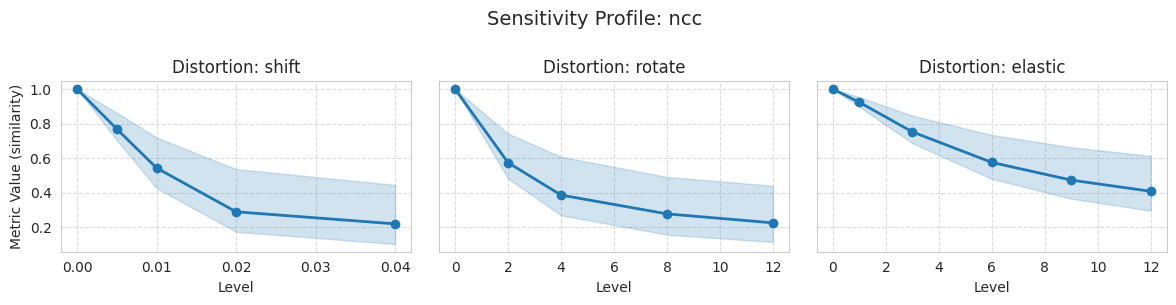

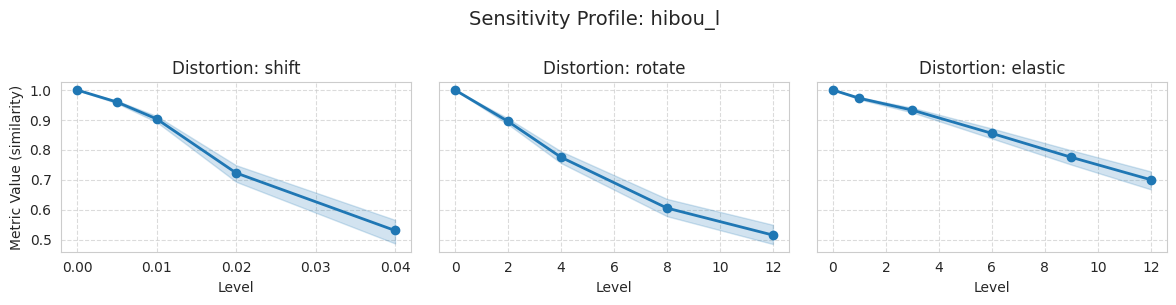

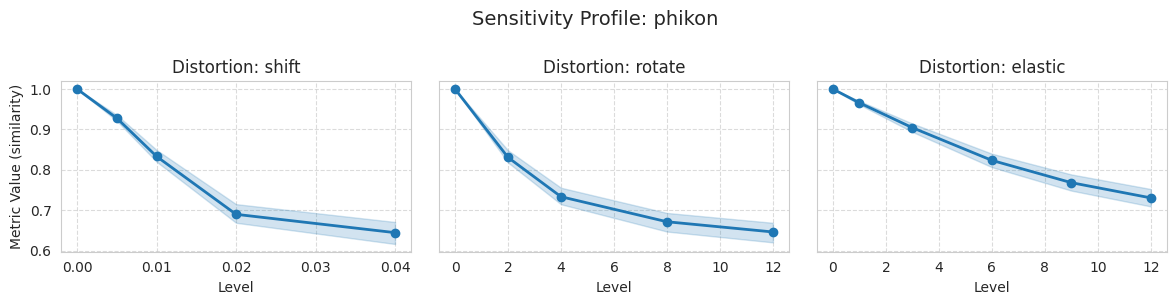

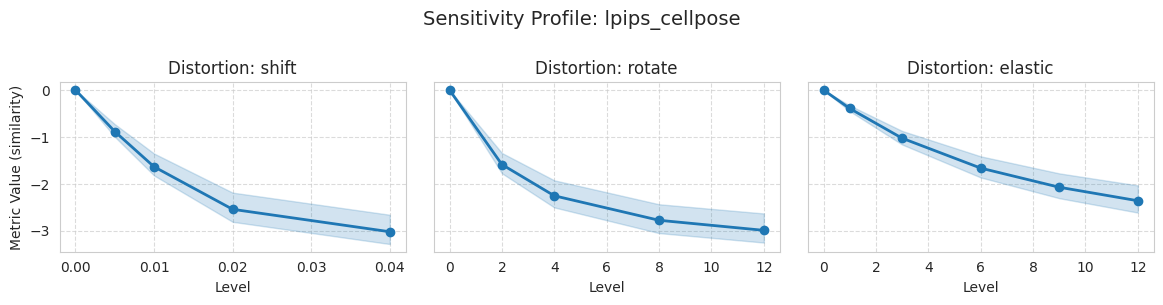

In [24]:
plot_sensitivity_profiles(df_fm_res)

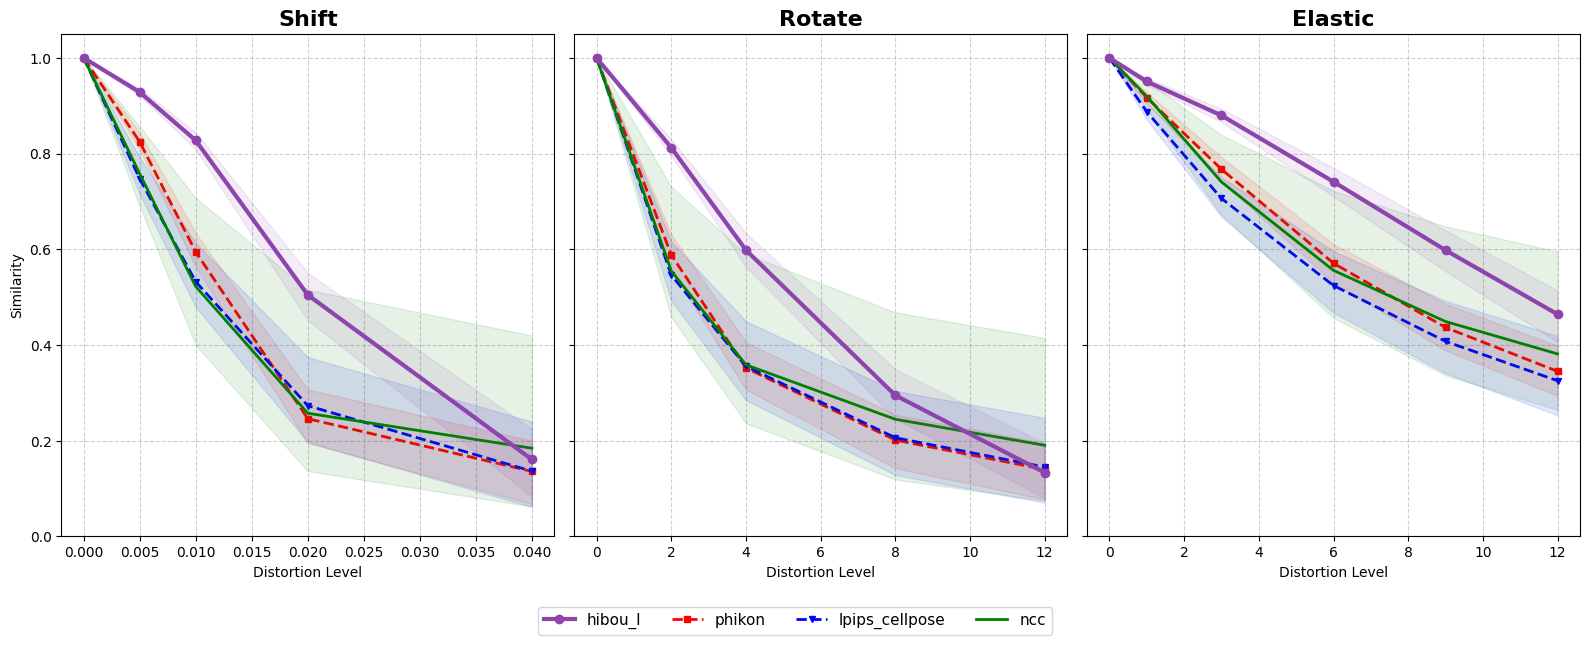

In [27]:
style_map = {
    # Proposed
    'hibou_l':        {'color': '#8e44ad', 'lw': 3, 'ls': '-', 'marker': 'o', 'ms': 6, 'zorder': 10},
    'phikon':         {'color': 'red', 'lw': 2, 'ls': '--', 'marker': 's', 'ms': 4, 'zorder': 4},
    'lpips_cellpose': {'color': 'blue', 'lw': 2, 'ls': '--', 'marker': 'v', 'ms': 4, 'zorder': 4},
    'ncc':            {'color': 'green', 'lw': 2, 'ls': '-', 'marker': None, 'zorder': 5},
}

plot_combined_sensitivity(df_fm_res, metrics=['hibou_l', 'phikon', 'lpips_cellpose', 'ncc'], norm=True, style_map=style_map)

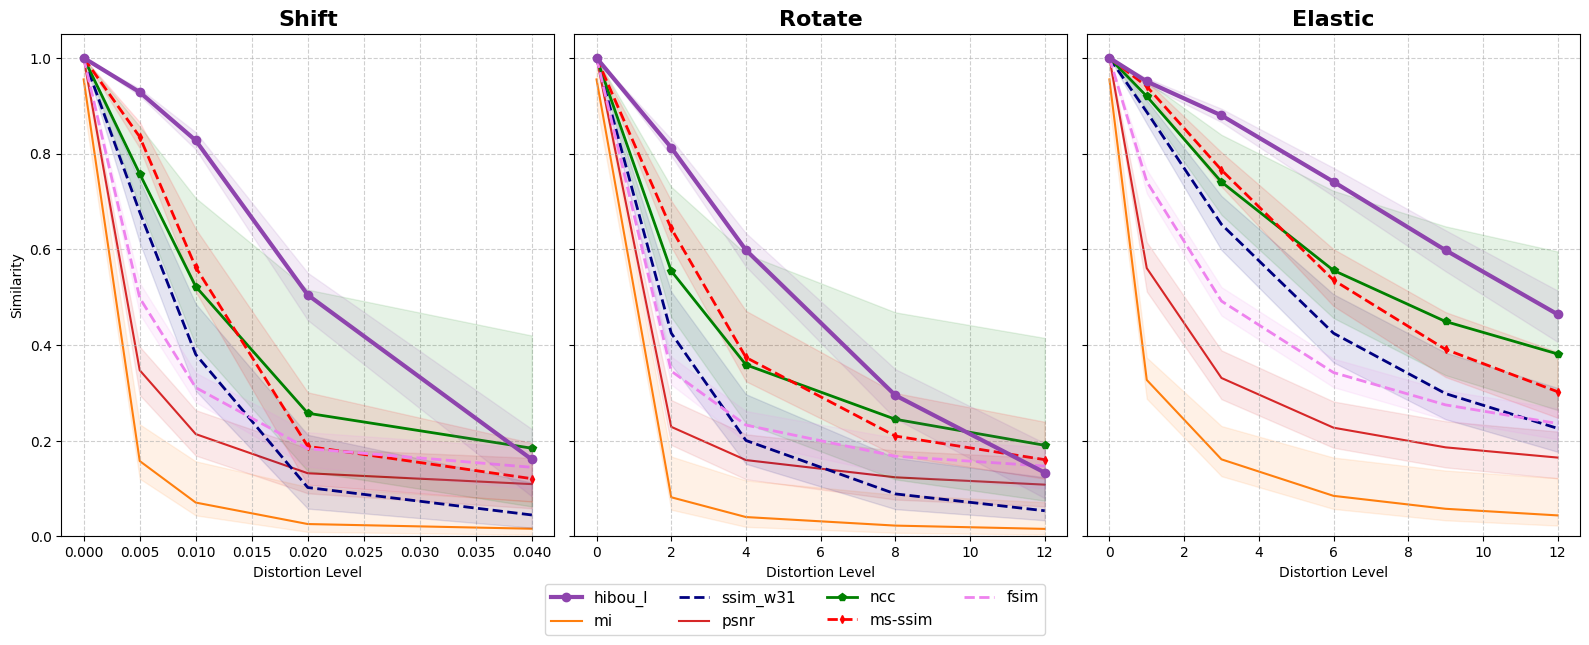

In [35]:
# All metrics were normalized by their 1th and 99th percentiles (min-max) to match the similarity scale [0, 1].
df_test = pd.concat([df_fm_res[df_fm_res['metric'] != 'ncc'], df_res], ignore_index=True)

plot_combined_sensitivity(df_test, metrics=['hibou_l', 'mi', 'ssim_w31', 'psnr', 'ncc', 'ms-ssim', 'fsim'], norm=True, style_map=style_map)

In [36]:
# 1. Списки метрик для отображения
sim_metrics = ['ssim_w31', 'ms-ssim', 'ncc', 'fsim']
dist_metrics = ['dists', 'dists_rgb', 'lpips_squeeze_avg', 'lpips_squeeze_avg_rgb',
                'lpips_alex_lin', 'lpips_alex_lin_rgb', 'lpips_vgg_lin', 'lpips_vgg_lin_rgb',
                'lpips_cellpose',]

# Настройка стилей (Визуальная иерархия)
# Цвета: Классика - Серые/Синие, Глубокие SOTA - Зеленые/Оранжевые, HAPS - Фиолетовый/Красный
style_map = {
    # Proposed
    'hibou_l': {'color': '#8e44ad', 'lw': 3, 'ls': '-', 'marker': 'o', 'ms': 6, 'zorder': 10},
    # Perceptual 
    'lpips_alex_lin_rgb':    {'color': 'goldenrod', 'lw': 2, 'ls': '--', 'marker': 's', 'ms': 4, 'zorder': 4},
    'lpips_vgg_lin_rgb':     {'color': 'blue', 'lw': 2, 'ls': '--', 'marker': 's', 'ms': 4, 'zorder': 4},
    'lpips_squeeze_avg_rgb': {'color': 'darkcyan', 'lw': 2, 'ls': '--', 'marker': 'v', 'ms': 4, 'zorder': 4},
    'dists_rgb':             {'color': 'red', 'lw': 2, 'ls': '--', 'marker': '^', 'ms': 4, 'zorder': 4},
    # Classical
    'ms-ssim':           {'color': 'red', 'lw': 2, 'ls': '--', 'marker': 'd', 'ms': 4, 'zorder': 5}, 
    'fsim':              {'color': 'violet', 'lw': 2, 'ls': '--', 'marker': None, 'ms': 4, 'zorder': 5}, 
    'ssim_w31':          {'color': 'navy', 'lw': 2, 'ls': '--', 'marker': None, 'ms': 4, 'zorder': 5},  
    'ncc':               {'color': 'green', 'lw': 2, 'ls': '-', 'marker': 'p', 'zorder': 5},
}

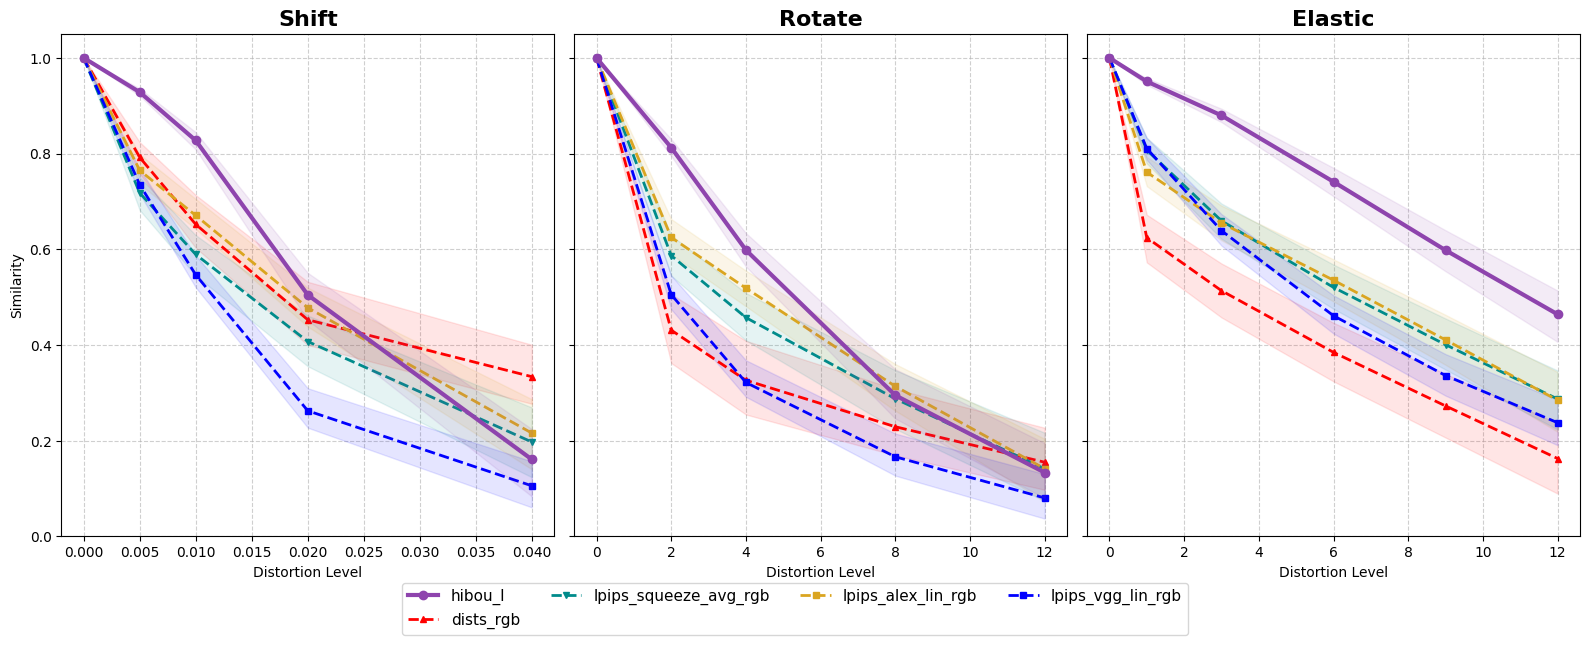

In [37]:
# Distance-based metrics (LPIPS, DISTS) were normalized by their 99th percentile and inverted to match the similarity scale [0, 1].
baseline_metrics = ['dists_rgb', 'lpips_squeeze_avg_rgb', 'lpips_alex_lin_rgb', 'lpips_vgg_lin_rgb']

plot_combined_sensitivity(df_test, metrics=['hibou_l'] + baseline_metrics, norm=True, style_map=style_map)

### LPIPS, DISTS - gray vs rgb congifs

Results:

- `DISTS` - no difference between configs
- `LPIPS_squeeze` - rgb config is better in all cases
- `LPIPS_alex` - rgb config is better in all cases
- `LPIPS_vgg` - rgb config is slightly better in all cases

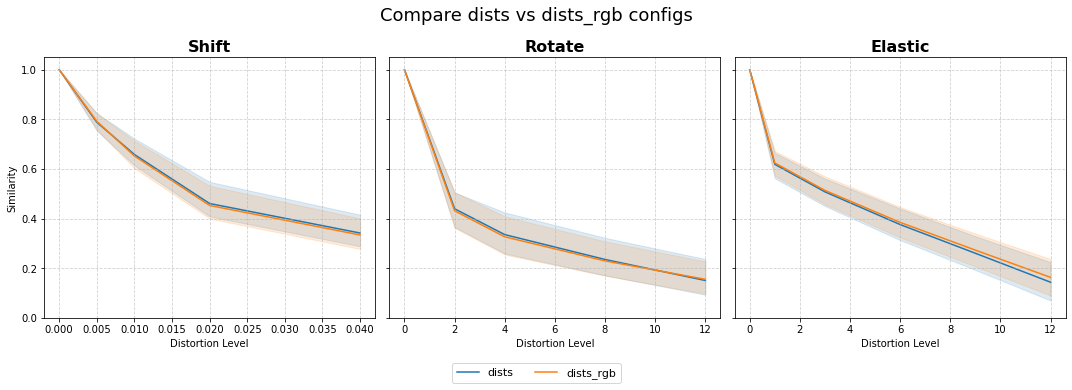

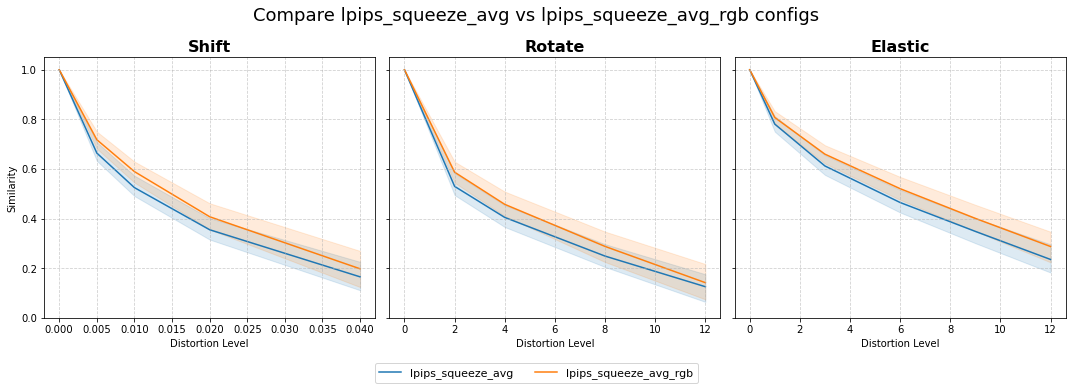

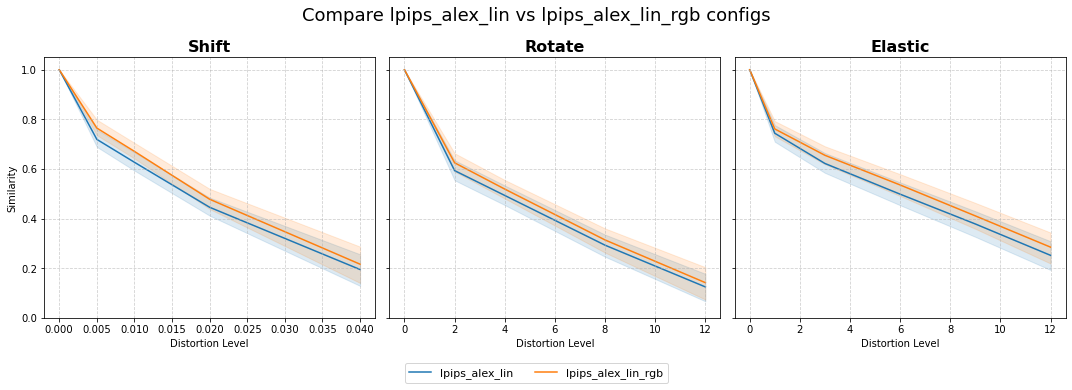

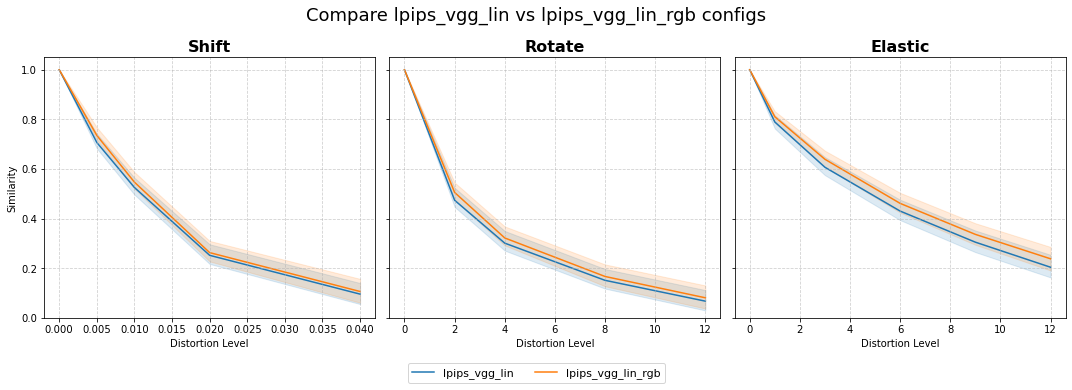

In [40]:
for mname in ['dists', 'lpips_squeeze_avg', 'lpips_alex_lin', 'lpips_vgg_lin']:
    title = f"Compare {mname} vs {mname}_rgb configs"
    metrics_list = [mname, f'{mname}_rgb']
    plot_combined_sensitivity(df_per_res, metrics=metrics_list, dist_metrics=metrics_list, style_map=None, title=title, figsize=(15, 5))

## Индексы чувствительности

- **Early Saturation** $ES_k = \frac{V_k-V_0}{V_{max}-V_0}$ — доля общего изменения, накопленная уже к уровню k (меньше = устойчивее к малым искажениям).
- **Late Sensitivity Ratio** $LSR = \frac{Slope_{last}}{Slope_{globak}}$ — ≈1 линейно, <1 насыщение, >1 ускорение на больших искажениях.

    $Slope_{last} = \frac{|V_{max}-V_{prev}|}{Level_{max}-Level_{prev}}$
    $Slope_{global} = \frac{|V_{max}-V_0|}{Level_{max}}$

In [47]:
show_metrics = ['ssim_w31', 'psnr', 'ncc', 'ms-ssim', 'fsim', 
                'dists_rgb', 'lpips_squeeze_avg_rgb', 'lpips_alex_lin_rgb', 'lpips_vgg_lin_rgb']

df_test = pd.concat([df_fm_res, df_res[df_res['metric'].isin(show_metrics)]], ignore_index=True)
indices_df = calculate_sensitivity_indices(df_test)
df = indices_df.round(3)

# Pivot: Index=Metric, Columns=(Distortion, IndexType)
cols_to_show = [c for c in df.columns if 'ES' in c or 'LSR' in c]
pivot = df.pivot_table(index='Metric', columns='Distortion', values=cols_to_show)
pivot.sort_values(by=[('ES_k1', 'rotate')])

ES_k1                 ES_k2                 ES_k3  \
Distortion            elastic rotate  shift elastic rotate  shift elastic   
Metric                                                                      
hibou_l                 0.092  0.216  0.085   0.224  0.463  0.206   0.483   
ms-ssim                 0.085  0.425  0.188   0.336  0.746  0.498   0.666   
lpips_alex_lin_rgb      0.334  0.437  0.300   0.482  0.561  0.420   0.649   
phikon                  0.127  0.478  0.203   0.355  0.753  0.469   0.655   
lpips_squeeze_avg_rgb   0.270  0.481  0.352   0.478  0.632  0.512   0.673   
lpips_cellpose          0.167  0.531  0.293   0.435  0.754  0.541   0.705   
lpips_vgg_lin_rgb       0.248  0.538  0.296   0.473  0.738  0.507   0.707   
ncc                     0.130  0.550  0.297   0.419  0.792  0.586   0.718   
ssim_w31                0.146  0.608  0.337   0.449  0.845  0.649   0.743   
dists_rgb               0.449  0.673  0.312   0.581  0.797  0.522   0.735   
fsim                    0.338  0.767  0.586   0.665  0.900  0.805   0.861   
psnr                    0.526  0.865  0.733   0.801  0.942  0.883   0.925   

                                    LSR_last               LSR_penult         \
Distortion            rotate  shift  elastic rotate  shift    elastic rotate   
Metric                                                                         
hibou_l                0.814  0.590    1.000  0.559  0.819      1.034  0.805   
ms-ssim                0.941  0.923    0.507  0.176  0.154      0.669  0.382   
lpips_alex_lin_rgb     0.799  0.666    0.705  0.602  0.668      0.701  0.659   
phikon                 0.928  0.872    0.560  0.215  0.255      0.690  0.370   
lpips_squeeze_avg_rgb  0.830  0.738    0.637  0.511  0.523      0.654  0.552   
lpips_cellpose         0.928  0.842    0.488  0.215  0.317      0.590  0.370   
lpips_vgg_lin_rgb      0.907  0.825    0.517  0.280  0.351      0.586  0.393   
ncc                    0.933  0.910    0.438  0.202  0.179      0.564  0.312   
ssim_w31               0.963  0.940    0.375  0.112  0.120      0.514  0.233   
dists_rgb              0.912  0.821    0.525  0.263  0.357      0.530  0.304   
fsim                   0.976  0.954    0.204  0.072  0.091      0.279  0.151   
psnr                   0.983  0.974    0.102  0.052  0.051      0.150  0.086   

                              
Distortion             shift  
Metric                        
hibou_l                1.059  
ms-ssim                0.670  
lpips_alex_lin_rgb     0.773  
phikon                 0.708  
lpips_squeeze_avg_rgb  0.651  
lpips_cellpose         0.611  
lpips_vgg_lin_rgb      0.657  
ncc                    0.552  
ssim_w31               0.468  
dists_rgb              0.637  
fsim                   0.260  
psnr                   0.157